# Laboratorio 03: Intuicion estadistica

**Estudiante:** Juan Montoya

Este laboratorio estudia la seleccion de un clasificador SVC con kernel RBF sobre datos sinteticos de dos distribuciones gaussianas. Se reserva un conjunto de prueba desde el comienzo: la seleccion de `gamma` usa solamente entrenamiento y validacion.

## Objetivos

1. Separar los datos en 70% entrenamiento, 10% validacion y 20% prueba; seleccionar `gamma` con una curva de score.
2. Construir curvas de aprendizaje y contrastar la seleccion manual con `GridSearchCV`.
3. Aplicar el modelo seleccionado a dos distribuciones nuevas para estudiar sobreajuste y subajuste.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, StratifiedKFold, learning_curve, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25

## Datos y funciones auxiliares

Cada clase es una normal bivariada. Las covarianzas con correlaciones opuestas producen una frontera no lineal, por lo que un SVC-RBF es una eleccion razonable. El escalado se incluye dentro de `Pipeline` para que cada ajuste calcule sus parametros solo con los datos que le corresponden.

In [2]:
def generar_datos(mu_0, cov_0, mu_1, cov_1, n_por_clase, seed):
    """Genera dos clases gaussianas balanceadas y las mezcla."""
    generador = np.random.default_rng(seed)
    x_0 = generador.multivariate_normal(mu_0, cov_0, n_por_clase)
    x_1 = generador.multivariate_normal(mu_1, cov_1, n_por_clase)
    X = np.vstack([x_0, x_1])
    y = np.r_[np.zeros(n_por_clase, dtype=int), np.ones(n_por_clase, dtype=int)]
    orden = generador.permutation(len(y))
    return X[orden], y[orden]

def modelo_svc(gamma):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('svc', SVC(kernel='rbf', gamma=gamma, C=1.0)),
    ])

def graficar_frontera(ax, modelo, X, y, titulo):
    margen = 0.7
    x_min, x_max = X[:, 0].min() - margen, X[:, 0].max() + margen
    y_min, y_max = X[:, 1].min() - margen, X[:, 1].max() + margen
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], cmap='coolwarm', alpha=0.22)
    ax.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=1.2)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c='tab:blue', label='Clase 0', edgecolor='white', s=32)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c='tab:red', label='Clase 1', edgecolor='white', s=32)
    ax.set(xlabel='$X_1$', ylabel='$X_2$', title=titulo)
    ax.legend(loc='best')

## 1. Seleccion manual de `gamma`

Primero se reserva 20% para prueba. El 80% restante se divide en 70% del total para entrenamiento y 10% del total para validacion. El conjunto de prueba se mantiene oculto hasta elegir el hiperparametro.

In [3]:
mu_0 = [1.2, 1.4]
cov_0 = [[1.0, -0.8], [-0.8, 1.0]]
mu_1 = [1.4, -1.4]
cov_1 = [[1.0, 0.8], [0.8, 1.0]]
X, y = generar_datos(mu_0, cov_0, mu_1, cov_1, n_por_clase=250, seed=SEED)

X_desarrollo, X_prueba, y_desarrollo, y_prueba = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
X_entrenamiento, X_validacion, y_entrenamiento, y_validacion = train_test_split(
    X_desarrollo, y_desarrollo, test_size=0.125, stratify=y_desarrollo, random_state=SEED
)

print(f'Total: {len(y)} muestras')
print(f'Entrenamiento: {len(y_entrenamiento)} ({len(y_entrenamiento) / len(y):.0%})')
print(f'Validacion: {len(y_validacion)} ({len(y_validacion) / len(y):.0%})')
print(f'Prueba: {len(y_prueba)} ({len(y_prueba) / len(y):.0%})')

Total: 500 muestras
Entrenamiento: 350 (70%)
Validacion: 50 (10%)
Prueba: 100 (20%)


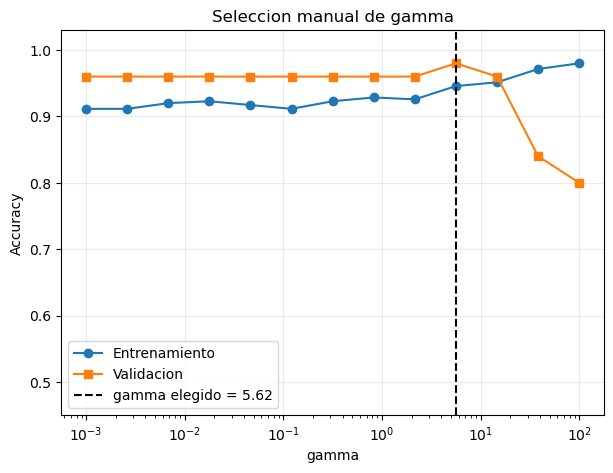

Mejor gamma por validacion: 5.62
Accuracy de validacion: 0.980


In [4]:
gammas = np.logspace(-3, 2, 13)
score_entrenamiento = []
score_validacion = []

for gamma in gammas:
    modelo = modelo_svc(gamma)
    modelo.fit(X_entrenamiento, y_entrenamiento)
    score_entrenamiento.append(modelo.score(X_entrenamiento, y_entrenamiento))
    score_validacion.append(modelo.score(X_validacion, y_validacion))

score_entrenamiento = np.array(score_entrenamiento)
score_validacion = np.array(score_validacion)
gamma_manual = gammas[np.argmax(score_validacion)]

plt.semilogx(gammas, score_entrenamiento, 'o-', label='Entrenamiento')
plt.semilogx(gammas, score_validacion, 's-', label='Validacion')
plt.axvline(gamma_manual, color='black', linestyle='--', label=f'gamma elegido = {gamma_manual:.3g}')
plt.xlabel('gamma'); plt.ylabel('Accuracy'); plt.title('Seleccion manual de gamma')
plt.ylim(0.45, 1.03); plt.legend(); plt.show()

print(f'Mejor gamma por validacion: {gamma_manual:.3g}')
print(f'Accuracy de validacion: {score_validacion.max():.3f}')

La solucion se elige por el maximo de validacion, no por el score de entrenamiento. Si `gamma` es demasiado grande, el score de entrenamiento puede subir mientras el de validacion deja de mejorar o disminuye: esa separacion es evidencia de sobreajuste.

Accuracy final en prueba: 0.960


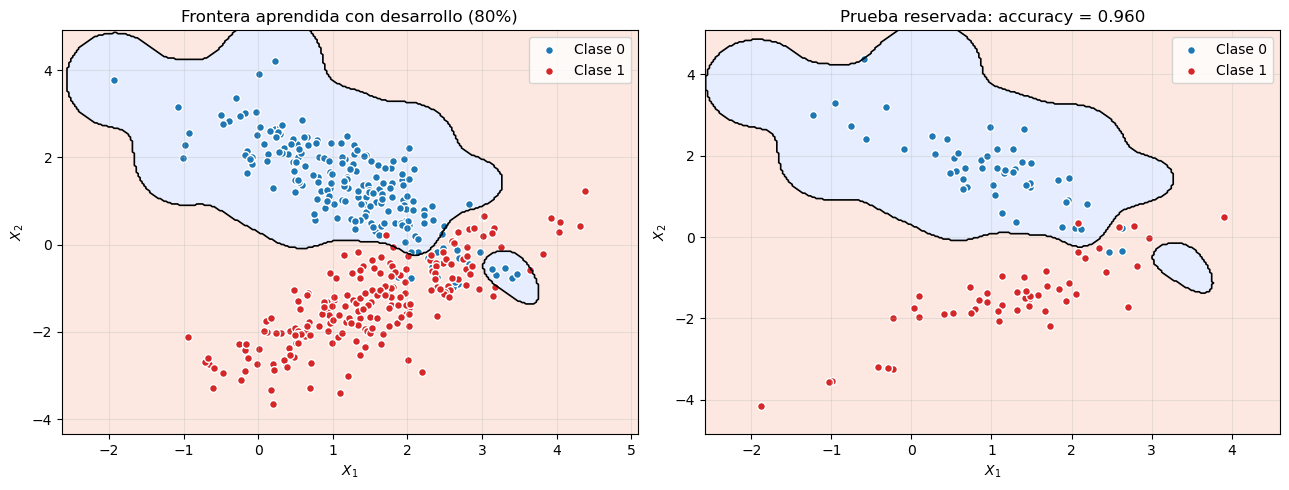

In [5]:
modelo_final = modelo_svc(gamma_manual)
modelo_final.fit(X_desarrollo, y_desarrollo)
score_prueba = modelo_final.score(X_prueba, y_prueba)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
graficar_frontera(axes[0], modelo_final, X_desarrollo, y_desarrollo, 'Frontera aprendida con desarrollo (80%)')
graficar_frontera(axes[1], modelo_final, X_prueba, y_prueba, f'Prueba reservada: accuracy = {score_prueba:.3f}')
plt.tight_layout()
print(f'Accuracy final en prueba: {score_prueba:.3f}')

El conjunto de prueba no participa en la seleccion de `gamma`. Se usa despues para evaluar modelos cuyos hiperparametros ya fueron fijados con datos de desarrollo.

## 2. Curvas de aprendizaje y comprobacion con GridSearchCV

La curva de aprendizaje usa solo los datos de desarrollo. Muestra como cambian los scores promedio de entrenamiento y validacion cruzada al aumentar el numero de ejemplos.

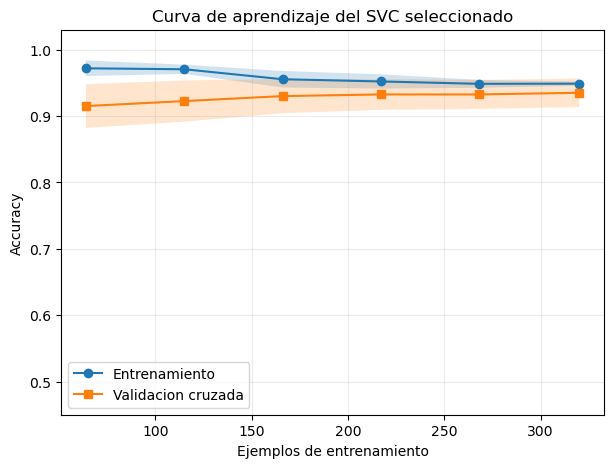

Con todos los datos de desarrollo: train = 0.949, CV = 0.935


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tam_train, scores_train, scores_cv = learning_curve(
    modelo_svc(gamma_manual), X_desarrollo, y_desarrollo,
    cv=cv, train_sizes=np.linspace(0.2, 1.0, 6), scoring='accuracy',
    shuffle=True, random_state=SEED
)
media_train, desv_train = scores_train.mean(axis=1), scores_train.std(axis=1)
media_cv, desv_cv = scores_cv.mean(axis=1), scores_cv.std(axis=1)

plt.plot(tam_train, media_train, 'o-', label='Entrenamiento')
plt.fill_between(tam_train, media_train - desv_train, media_train + desv_train, alpha=0.2)
plt.plot(tam_train, media_cv, 's-', label='Validacion cruzada')
plt.fill_between(tam_train, media_cv - desv_cv, media_cv + desv_cv, alpha=0.2)
plt.xlabel('Ejemplos de entrenamiento'); plt.ylabel('Accuracy')
plt.title('Curva de aprendizaje del SVC seleccionado')
plt.ylim(0.45, 1.03); plt.legend(); plt.show()

print(f'Con todos los datos de desarrollo: train = {media_train[-1]:.3f}, CV = {media_cv[-1]:.3f}')

Comparacion de la seleccion de gamma
Manual       | gamma = 5.62 | CV = 0.935 | prueba = 0.960
GridSearchCV | gamma = 14.7 | CV = 0.940 | prueba = 0.940
Los valores estan separados por 1 paso logaritmico (factor 2.61).
Diferencia de accuracy en prueba (Grid - manual): -0.020
La prueba compara dos modelos ya seleccionados; no se usa para escoger gamma.


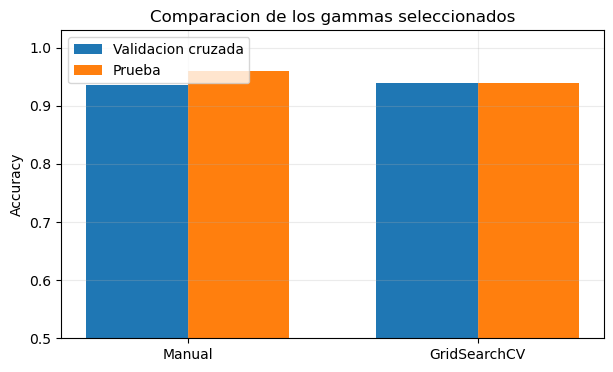

In [7]:
busqueda = GridSearchCV(
    estimator=modelo_svc(gamma=1.0),
    param_grid={'svc__gamma': gammas},
    cv=cv, scoring='accuracy', n_jobs=-1
)
busqueda.fit(X_desarrollo, y_desarrollo)
gamma_grid = busqueda.best_params_['svc__gamma']
modelo_grid = busqueda.best_estimator_

# Comparamos ambos candidatos con la misma validacion cruzada de cinco particiones.
gammas_cv = np.asarray(busqueda.cv_results_['param_svc__gamma'], dtype=float)
indice_manual = np.flatnonzero(np.isclose(gammas_cv, gamma_manual))[0]
indice_grid = np.flatnonzero(np.isclose(gammas_cv, gamma_grid))[0]
cv_manual = busqueda.cv_results_['mean_test_score'][indice_manual]
cv_grid = busqueda.cv_results_['mean_test_score'][indice_grid]

# Los dos modelos ya fueron fijados usando desarrollo; prueba se usa solo para compararlos.
score_prueba_manual = score_prueba
score_prueba_grid = modelo_grid.score(X_prueba, y_prueba)
factor_gamma = gamma_grid / gamma_manual
pasos_en_grilla = abs(indice_grid - indice_manual)

print('Comparacion de la seleccion de gamma')
print(f'Manual       | gamma = {gamma_manual:.3g} | CV = {cv_manual:.3f} | prueba = {score_prueba_manual:.3f}')
print(f'GridSearchCV | gamma = {gamma_grid:.3g} | CV = {cv_grid:.3f} | prueba = {score_prueba_grid:.3f}')
print(f'Los valores estan separados por {pasos_en_grilla} paso logaritmico (factor {factor_gamma:.2f}).')
print(f'Diferencia de accuracy en prueba (Grid - manual): {score_prueba_grid - score_prueba_manual:+.3f}')
print('La prueba compara dos modelos ya seleccionados; no se usa para escoger gamma.')

fig, ax = plt.subplots(figsize=(7, 4))
posiciones = np.arange(2)
ancho = 0.35
ax.bar(posiciones - ancho / 2, [cv_manual, cv_grid], ancho, label='Validacion cruzada')
ax.bar(posiciones + ancho / 2, [score_prueba_manual, score_prueba_grid], ancho, label='Prueba')
ax.set_xticks(posiciones, ['Manual', 'GridSearchCV'])
ax.set_ylim(0.5, 1.03)
ax.set_ylabel('Accuracy')
ax.set_title('Comparacion de los gammas seleccionados')
ax.legend()
plt.show()

`GridSearchCV` no tiene por que elegir exactamente el mismo valor que la validacion unica: promedia cinco particiones distintas, mientras que la seleccion manual usa una sola. En esta ejecucion, la seleccion manual eligio `gamma=5.62` y `GridSearchCV` eligio `gamma=14.7`; son valores adyacentes de la grilla logaritmica. La validacion cruzada favorecio levemente a `GridSearchCV` (0.940 frente a 0.935), mientras que el conjunto de prueba favorecio al modelo manual (0.960 frente a 0.940). Esa diferencia en prueba equivale a dos observaciones de 100 y no debe usarse para volver a elegir `gamma`: la prueba solo confirma que ambas opciones tienen desempenos cercanos y que la seleccion manual es consistente con la busqueda sistematica.

## 3. El mismo modelo ante distribuciones nuevas

Se conserva la misma familia de modelo, SVC-RBF. En el primer experimento se usa el `gamma` seleccionado anteriormente; en el segundo se usa un `gamma` deliberadamente bajo para evidenciar que una frontera demasiado suave no recupera la estructura nueva. Se reportan scores de entrenamiento y prueba: la diferencia entre ambos permite diagnosticar el comportamiento.

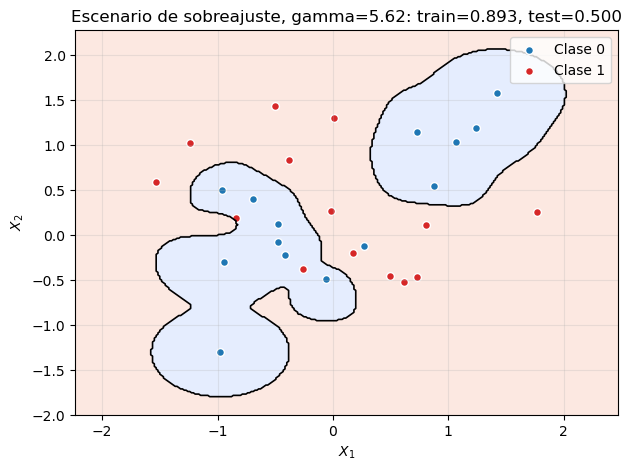

Escenario de sobreajuste | gamma: 5.62; entrenamiento: 0.893; prueba: 0.500; brecha: +0.393


In [8]:
def evaluar_escenario(nombre, parametros, n_por_clase, gamma, seed):
    X_esc, y_esc = generar_datos(*parametros, n_por_clase=n_por_clase, seed=seed)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_esc, y_esc, test_size=0.35, stratify=y_esc, random_state=seed
    )
    modelo = modelo_svc(gamma)
    modelo.fit(X_tr, y_tr)
    score_tr = modelo.score(X_tr, y_tr)
    score_te = modelo.score(X_te, y_te)
    fig, ax = plt.subplots(figsize=(7, 5))
    graficar_frontera(ax, modelo, X_tr, y_tr, f'{nombre}, gamma={gamma:.3g}: train={score_tr:.3f}, test={score_te:.3f}')
    plt.show()
    print(f'{nombre} | gamma: {gamma:.3g}; entrenamiento: {score_tr:.3f}; prueba: {score_te:.3f}; brecha: {score_tr - score_te:+.3f}')
    return score_tr, score_te

# Pocas observaciones de distribuciones muy solapadas: el modelo puede adaptarse al ruido de la muestra.
parametros_sobreajuste = (
    [-0.35, 0.0], [[1.0, 0.65], [0.65, 1.0]],
    [0.35, 0.0], [[1.0, -0.65], [-0.65, 1.0]],
)
score_sobre_train, score_sobre_test = evaluar_escenario(
    'Escenario de sobreajuste', parametros_sobreajuste, n_por_clase=22, gamma=gamma_manual, seed=7
)

En el escenario de sobreajuste se esperan un score de entrenamiento claramente mayor que el de prueba y una frontera sensible a pocos puntos. El solapamiento establece ademas un error Bayesiano que ningun clasificador puede hacer cero.

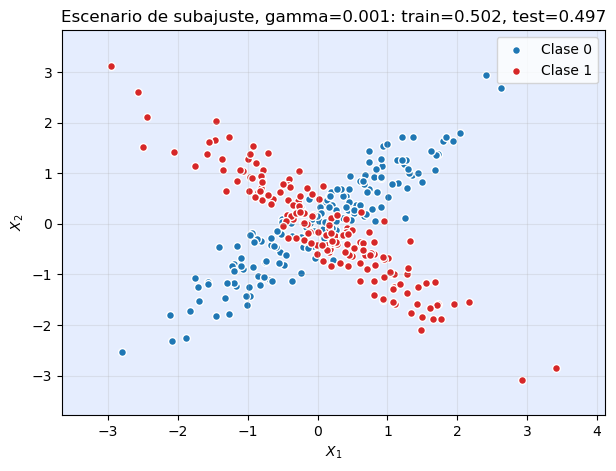

Escenario de subajuste | gamma: 0.001; entrenamiento: 0.502; prueba: 0.497; brecha: +0.004


In [9]:
# Covarianzas opuestas y medias cercanas generan una separacion curvada. Un gamma muy bajo impone una frontera demasiado suave.
parametros_subajuste = (
    [0.0, 0.0], [[1.0, 0.92], [0.92, 1.0]],
    [0.0, 0.0], [[1.0, -0.92], [-0.92, 1.0]],
)
score_sub_train, score_sub_test = evaluar_escenario(
    'Escenario de subajuste', parametros_subajuste, n_por_clase=250, gamma=0.001, seed=19
)

### Analisis final

- **Sobreajuste:** se identifica cuando el score de entrenamiento es alto y la brecha con prueba es grande. Tener pocas observaciones facilita que la frontera se adapte a fluctuaciones particulares de la muestra.
- **Subajuste:** se identifica cuando entrenamiento y prueba son ambos bajos y cercanos. En este caso gamma=0.001 hace que el SVC-RBF sea demasiado suave para la frontera curvada. Agregar datos por si solo no corrige el problema; se necesita una frontera mas expresiva o volver a seleccionar gamma para la nueva distribucion.
- El valor de gamma no es universal: se eligio para el primer conjunto de gaussianas. Cambiar medias, covarianzas o cantidad de datos cambia el compromiso sesgo-varianza y obliga a validar de nuevo.
- El test reservado solo sirve para la evaluacion final. Elegir gamma con test produciria una estimacion optimista de generalizacion.